In [1]:
# =============================================================================
# P-LORAKS: Structured Low-Rank Matrix Modeling of Local k-Space Neighborhoods
# Designed for calibrationless parallel imaging reconstruction
# from undersampled multi-coil k-space data.

# This code implements the P-LORAKS algorithm for MRI reconstruction, which
# exploits the local low-rank structure in multi-coil k-space by incorporating
# support, phase, and parallel imaging constraints. It enables reconstruction
# of accelerated acquisitions without explicit calibration.

# Hyperparameters:
#   VCC       : Enable Virtual Conjugate Coils (bool), improves reconstruction
#               by exploiting k-space conjugate symmetry.
#   R         : Kernel radius for local k-space neighborhoods; larger R
#               captures more spatial context but increases computation.
#   lambda_   : Regularization weight balancing data consistency vs. low-rank
#               constraint; higher values impose stronger low-rank prior.
#   tol       : Convergence tolerance for relative error in iterative updates.
#   max_iter  : Maximum number of iterations allowed for reconstruction loop.
#   r_C       : Target rank for low-rank approximation of k-space patches.

# Reference:
#   Haldar JP, Zhuo J. "P-LORAKS: Low-rank modeling of local k-space 
#   neighborhoods with parallel imaging data."
#   Magnetic Resonance in Medicine. 2016;75(4):1499-1514.

# =============================================================================

import numpy as np
from numpy import linalg as LA
from scipy.io import loadmat
from scipy.sparse.linalg import eigsh, eigs
import h5py
import matplotlib.pyplot as plt

# load defined functions from utils.py
from utils import *

In [2]:

# -------------------------- Library Functions ---------------------------------

def svdsecon(X, k):
    """
    Compute low-rank SVD approximation using top-k singular values.
    """
    m, n = X.shape
    assert k <= m and k <= n, "k must be smaller than min(X.shape)"

    if m <= n:
        # Compute covariance C = X @ X^H for tall or square matrices
        C = X @ X.conj().T
        try:
            eigvals, U = eigsh(C, k=k, which='LM')
        except:
            eigvals, U = eigs(C, k=k, which='LM')
        idx = np.argsort(-np.abs(eigvals))
        eigvals, U = eigvals[idx], U[:, idx]
        s = np.sqrt(np.abs(eigvals))
        V = (X.conj().T @ U) / s[np.newaxis, :]
        S = np.diag(s)
    else:
        # Compute covariance C = X^H @ X for wide matrices
        C = X.conj().T @ X
        try:
            eigvals, V = eigsh(C, k=k, which='LM')
        except:
            eigvals, V = eigs(C, k=k, which='LM')
        idx = np.argsort(-np.abs(eigvals))
        eigvals, V = eigvals[idx], V[:, idx]
        s = np.sqrt(np.abs(eigvals))
        U = (X @ V) / s[np.newaxis, :]
        S = np.diag(s)

    return U, S, V




def ktoM(kdata, R):
    """
    Convert multi-channel kspace to Henkel matrix using circular patches of radius R.
    """
    H, W, C = kdata.shape
    y, x = np.ogrid[-R:R+1, -R:R+1]
    mask = (x**2 + y**2 <= R**2)
    mask_flat = mask.flatten()
    num_pixels = np.sum(mask_flat)

    num_patches = (H - 2*R) * (W - 2*R)
    patches = np.zeros((num_pixels * C, num_patches), dtype=np.complex64)

    patch_idx = 0
    for i in range(R, H-R):
        for j in range(R, W-R):
            patch_block = kdata[i-R:i+R+1, j-R:j+R+1, :]  # shape (2R+1, 2R+1, C)
            patch_block_flat = patch_block.reshape(-1, C)  # shape (n*n, C)
            masked_patch = patch_block_flat[mask_flat, :]  # circular mask
            patches[:, patch_idx] = masked_patch.T.reshape(-1)
            patch_idx += 1
    return patches

def Mtok(patch_matrix, image_shape, R):
    """
    Reconstruct multi-channel kspace from Henkel matrix.
    """
    H, W, C = image_shape
    y, x = np.ogrid[-R:R+1, -R:R+1]
    mask = (x**2 + y**2 <= R**2)
    mask_flat = mask.flatten()
    num_pixels = np.sum(mask_flat)
    n = 2 * R + 1

    img_recon = np.zeros((H, W, C), dtype=np.complex64)
    weight = np.zeros((H, W, C), dtype=np.float32)

    idx = 0
    for i in range(R, H-R):
        for j in range(R, W-R):
            patch_vec = patch_matrix[:, idx]  # shape (num_pixels * C,)
            # Reshape patch to (C, num_pixels)
            patch_by_channel = patch_vec.reshape(C, num_pixels)

            # Expand masked patch to (C, n*n) by creating n*n zeros and placing the masked values
            patch_block = np.zeros((C, n*n), dtype=np.complex64)
            patch_block[:, mask_flat] = patch_by_channel  # fill masked positions only

            # Reshape to (n, n, C) for direct placement in kspace
            patch_block_3d = patch_block.T.reshape(n, n, C)

            img_recon[i-R:i+R+1, j-R:j+R+1, :] += patch_block_3d
            weight[i-R:i+R+1, j-R:j+R+1, :] += mask[..., None].astype(np.float32)

            idx += 1

    return img_recon, weight

def apply_vcc(kData, kMask):
    """
    Apply Virtual Conjugate Coil (VCC) to kData/kMask.
    """
    _, _, C = kData.shape

    if kMask.ndim == 2:
        kMask = np.expand_dims(kMask, axis=-1)
    if kMask.shape[-1] == 1:
        kMask = np.tile(kMask, (1, 1, C))
    if kMask.shape[-1] != C:
        raise ValueError(f"kMask channels ({kMask.shape[-1]}) != kData channels ({C})")

    kData_vcc = np.flip(np.flip(np.conj(kData), axis=0), axis=1)
    kMask_vcc = np.flip(np.flip(kMask, axis=0), axis=1)

    augmented_kData = np.concatenate((kData, kData_vcc), axis=-1)
    augmented_kMask = np.concatenate((kMask, kMask_vcc), axis=-1)

    return augmented_kData, augmented_kMask

def inverse_vcc(augmented_recon, augmented_kData, augmented_kMask):
    """
    Undo VCC by flipping & conjugating the augmented VCC channels back to original orientation.
    Returns combined average of original and reverted VCC reconstructions.
    """
    _, _, doubled_C = augmented_recon.shape
    C = doubled_C // 2

    recon_orig = augmented_recon[:, :, :C]
    recon_vcc = augmented_recon[:, :, C:]
    recon_reverted = np.conj(np.flip(np.flip(recon_vcc, axis=0), axis=1))
    recon_combined = 0.5 * (recon_orig + recon_reverted)

    return recon_combined, augmented_kData[:, :, :C], augmented_kMask[:, :, :C]

def isumsq(kdata):
    """
    Convert multi-channel k-space data to magnitude image using root-sum-of-squares (rSoS).
    """
    img = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(kdata, axes=(0,1)), axes=(0,1)), axes=(0,1))
    return np.sqrt(np.sum(np.abs(img)**2, axis=-1))

def show(img, title):
    """
    Display grayscale image with matplotlib.
    """
    plt.imshow(img, cmap='gray')
    plt.title(title)
    plt.axis('off')



Loading data that should be in format : 
#### Required Inputs (`dataset.mat`)
| Name    | Shape              | Description                              |
|---------|--------------------|------------------------------------------|
| `kData` | `(nx, ny, nCoils)` | Undersampled multi-coil k-space data     |
| `kMask` | `(nx, ny)` or `(nx, ny, 1)` or `(nx, ny, nCoils)` | Binary sampling mask         |


# Test with data.mat in the scan_specific_dl folder

In [4]:
# ---------------------------- Data Load ---------------------------------------
data = loadmat('/data/data.mat')  # load data
kData = np.squeeze(data['kspace'], axis = 3)    #  k-space data
kData.shape

FileNotFoundError: [Errno 2] No such file or directory: '/data/data.mat'

In [4]:
kMask = data['mask']
kMask.shape

(320, 320, 1)

In [5]:

# -------------------------- Hyperparameters ----------------------------------
VCC = True           # Enable Virtual Conjugate Coils
R = 3                # Kernel radius
lambda_ = 1e-4       # Regularization weight
tol = 1e-4           # Iteration tolerance
max_iter = 1000      # Max iterations
r_C = 40             # Rank for low-rank constraint

# ---------------------------- Data Load ---------------------------------------
#kData = loadmat('dataset.mat')['kData']     # k-space data
#kMask = loadmat('dataset.mat')['kMask']     # Sampling Mask
if VCC:
    kData, kMask = apply_vcc(kData, kMask)

nx, ny, nc = kData.shape
acc = kMask.size / np.sum(kMask)
print(f"Acceleration factor: {acc:.2f}x")
kdata = kData * kMask

Acceleration factor: 3.27x


In [6]:
# ---------------------------- Initialization ----------------------------------
patches = ktoM(kdata, R)
weight = Mtok(patches, (nx, ny, nc), R)[1]
phi = kMask + lambda_ * weight
phi_dagger = np.zeros_like(phi)
phi_dagger[phi != 0] = 1.0 / phi[phi != 0]
z = kdata * kMask

In [7]:

# ------------------------ P-LORAKS Reconstruction -----------------------------
for i in range(1, max_iter+1):
    z_prev = z.copy()
    CC = ktoM(z, R)
    Ucc, Scc, Vcc = svdsecon(CC, k=r_C)
    CC_approx = Ucc @ Scc @ Vcc.conj().T
    CCr = Mtok(CC_approx, (nx, ny, nc), R)[0]

    z = phi_dagger * (kdata + lambda_ * CCr)
    t = LA.norm(z_prev - z) / LA.norm(z)

    if t < tol:
        print(f"Converged at iter {i}, t: {t:.2e}")
        break
    if i % 10 == 0:
        print(f"iter {i}, t: {t:.2e}")

recon = z
if VCC:
    recon, kData, kMask = inverse_vcc(recon, kData, kMask)

iter 10, t: 7.81e-03
iter 20, t: 2.98e-03
iter 30, t: 1.64e-03
iter 40, t: 9.83e-04
iter 50, t: 6.14e-04
iter 60, t: 3.93e-04
iter 70, t: 2.57e-04
iter 80, t: 1.71e-04
iter 90, t: 1.15e-04
Converged at iter 94, t: 9.90e-05


Done. Acc: 3.27x, Error: 2.76e-01, zp_Error: 6.29e-17


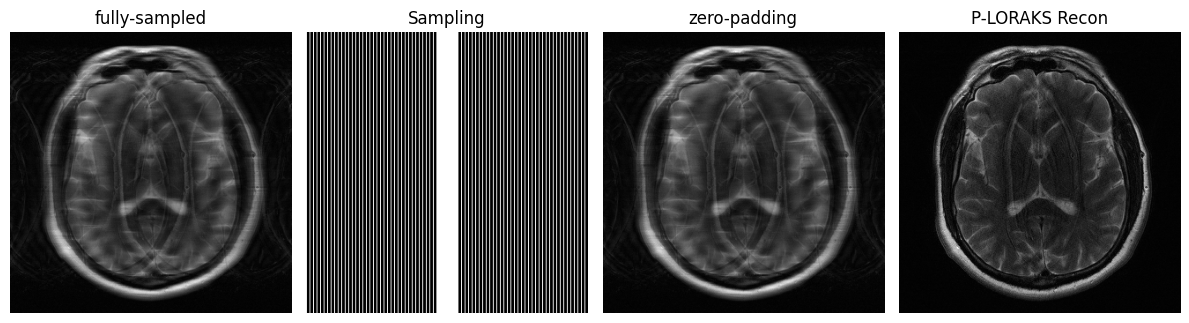

In [9]:

# -------------------------- Reconstruction Error ------------------------------
error = LA.norm(isumsq(recon) - isumsq(kData)) / LA.norm(isumsq(kData))
zp_error = LA.norm(isumsq(kData * kMask) - isumsq(kData)) / LA.norm(isumsq(kData))
print(f"Done. Acc: {acc:.2f}x, Error: {error:.2e}, zp_Error: {zp_error:.2e}")

# ------------------------------ Visualization ---------------------------------
plt.figure(figsize=(12, 4))
plt.subplot(1, 4, 1); show(isumsq(kData), "fully-sampled")
plt.subplot(1, 4, 2); show(kMask[...,0], "Sampling")
plt.subplot(1, 4, 3); show(isumsq(kData * kMask), "zero-padding")
plt.subplot(1, 4, 4); show(isumsq(recon), "P-LORAKS Recon")
plt.tight_layout()
plt.show()


# Test with h5 file from eda and basic reco notebook 
'file_brain_AXT2_205_2050058.h5'  
Opening file, getting the kspace from the middle slice and creating the mask

In [ ]:
file_path = "data/file_brain_AXT2_205_2050058.h5"
image_file = h5py.File(file_path)
kData_all = image_file['kspace'][()]
kData_all.shape

In [8]:
middle_index = kData_all.shape[0] //2
middle_slice_kspace = kData_all[middle_index] # Choosing the middle slice of this volume
middle_slice_kspace.shape



NameError: name 'kData_all' is not defined

In [ ]:
# Creating the mask

accel = 4   # acceleration factor
calib_region = 24
# Getting the shape of kspace from 1 coil and saving it as tuple
img_shape = middle_slice_kspace[0,:,:].shape
type(img_shape)

In [ ]:
img_shape

In [ ]:
# Creating a mask filled with 0 with shape of img_shape
msk = np.zeros(img_shape, dtype=float)  # Initialize with the correct shape
#msk.shape

# Fill with 1 each accel element, here each 4 element
msk[:, 0::accel] = 1   

# include the center of k-space
# calib_region = 24   # Calibration region size that was defined earlier
center_region = calib_region  # Size of the center region to keep
# modify the mask with 1 in the center region
msk[:, img_shape[1]//2 - center_region//2:img_shape[1]//2 + center_region//2] = 1

msk = msk[..., np.newaxis]  # Add dimensions to match kspace that is 3d array to have shape (320, 320, 1)
msk.shape
# mosaic(msk[:,:,0], 1, 1, 4, [0,1], '4x sampling mask', 0, 1)
plt.imshow(msk[:,:,0])

In [ ]:
kData = middle_slice_kspace
kMask = msk